# Phase 1 & 2 — Data Collection, Preparation and Exploratory Data Analysis

**Project:** AI-Powered Stock Market Trend & News Sentiment Analyzer

**Dataset source:** Yahoo Finance, downloaded through the `yfinance` package and cached in
`data/stock_data.csv` (free, no API key). Re-run `python -m src.data_loader` to refresh it.

| Symbol | Description | Role |
|---|---|---|
| `^NSEI` | NIFTY 50 index | market index |
| `RELIANCE.NS` | Reliance Industries Ltd | stock |
| `TCS.NS` | Tata Consultancy Services Ltd | stock |

**Phase 1 tasks:** load with pandas → convert `Date` to datetime → sort chronologically →
check missing values → check duplicates → handle invalid values → descriptive statistics →
percentage daily return.

In [2]:
from pathlib import Path
import sys

# make the project root importable no matter where the notebook is started from
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_columns", 60)

from src.data_loader import prepare, basic_stats, TICKERS, RAW_CSV

df = prepare()          # load -> clean -> daily return
print(f"raw file: {RAW_CSV}")
df.head()

Ticker list has changed.
Missing symbols in cached data: ['INFY.NS', 'JIOFIN.NS', 'RIIL.NS', 'TATACONSUM.NS', 'TATAPOWER.NS', 'TATASTEEL.NS']
Refreshing stock data...
Cached raw data -> C:\Users\PRERONA SINHA RAY\OneDrive\Desktop\stock_market_ai\Stock_Market_AI_Analyzer\data\stock_data.csv

--- Phase 1 cleaning report ---
  missing_before: {}
  duplicate_rows: 0
  missing_after: {}
  rows: 18127
  symbols: ['INFY.NS', 'JIOFIN.NS', 'RELIANCE.NS', 'RIIL.NS', 'TATACONSUM.NS', 'TATAPOWER.NS', 'TATASTEEL.NS', 'TCS.NS', '^NSEI']
  date_min: 2018-01-01
  date_max: 2026-10-07
raw file: C:\Users\PRERONA SINHA RAY\OneDrive\Desktop\stock_market_ai\Stock_Market_AI_Analyzer\data\stock_data.csv


Price,Date,Close,High,Low,Open,Volume,Symbol,Name,Daily_Return
0,2018-01-01,406.45,410.76,405.05,408.08,"5,431,340.00",INFY.NS,Infosys,NaN
1,2018-01-02,404.93,409.77,402.30,407.90,"6,112,248.00",INFY.NS,Infosys,-0.37
2,2018-01-03,401.63,405.68,400.57,404.46,"6,846,552.00",INFY.NS,Infosys,-0.82
3,2018-01-04,399.31,401.51,397.03,401.51,"8,947,614.00",INFY.NS,Infosys,-0.58
4,2018-01-05,397.97,403.64,395.61,399.27,"11,025,976.00",INFY.NS,Infosys,-0.33


## Phase 1 — cleaning report

Implemented in `src/data_loader.py`:

1. **Load** with pandas.
2. **`Date` → datetime** (timezone stripped, Yahoo returns tz-aware stamps).
3. **Sorted** by Symbol then Date, so every instrument is chronological.
4. **Missing values** counted per column before cleaning.
5. **Duplicates** on `(Symbol, Date)` removed.
6. **Invalid values** — non-positive prices and non-positive volume are treated as missing;
   prices are forward-filled then back-filled *inside each symbol*, volume forward-filled.
7. **Basic statistics** through `.describe()`.
8. **Percentage daily return** = `(Close[t] − Close[t−1]) / Close[t−1] × 100`.

In [3]:
report = pd.Series({
    "rows": len(df),
    "instruments": df["Symbol"].nunique(),
    "date range": f"{df['Date'].min().date()} -> {df['Date'].max().date()}",
    "missing values left": int(df.isna().sum().sum()),
    "duplicate (Symbol, Date) rows": int(df.duplicated(subset=["Symbol", "Date"]).sum()),
    "zero-volume sessions repaired": int((df["Volume"] == 0).sum()),
})
report

rows                                                18127
instruments                                             9
date range                       2018-01-01 -> 2026-10-07
missing values left                                     9
duplicate (Symbol, Date) rows                           0
zero-volume sessions repaired                           0
dtype: object

In [4]:
df[df.isna().any(axis=1)]

Price,Date,Close,High,Low,Open,Volume,Symbol,Name,Daily_Return
0,2018-01-01,406.45,410.76,405.05,408.08,"5,431,340.00",INFY.NS,Infosys,NaN
2170,2023-08-21,247.93,261.03,247.93,260.98,"74,715,306.00",JIOFIN.NS,Jio Financial Services,NaN
2948,2018-01-01,400.02,405.71,399.03,405.71,"9,453,202.00",RELIANCE.NS,Reliance Industries,NaN
5118,2018-01-01,609.10,616.14,515.59,516.55,"8,266,293.00",RIIL.NS,Reliance Industrial Infrastructure,NaN
7287,2018-01-01,290.46,295.00,289.43,294.96,"1,602,814.00",TATACONSUM.NS,Tata Consumer Products,NaN
9457,2018-01-01,86.56,89.10,82.33,83.58,"33,659,894.00",TATAPOWER.NS,Tata Power,NaN
11627,2018-01-01,54.16,55.15,53.96,54.94,"19,249,201.00",TATASTEEL.NS,Tata Steel,NaN
13797,2018-01-01,"1,063.44","1,083.22","1,059.18","1,078.19","1,351,760.00",TCS.NS,Tata Consultancy Services,NaN
15967,2018-01-02,"10,442.20","10,495.20","10,404.65","10,477.55","153,400.00",^NSEI,NIFTY 50,NaN


In [5]:
# 7. basic statistical information about the dataset
basic_stats(df)

Price             Open                                                  \
                 count      mean      std      min       25%       50%   
Symbol                                                                   
INFY.NS       2,170.00  1,136.57   413.21   399.27    651.02  1,260.53   
JIOFIN.NS       778.00    282.05    47.09   199.21    238.88    275.97   
RELIANCE.NS   2,170.00  1,021.17   341.62   385.62    676.07  1,108.15   
RIIL.NS       2,169.00    709.64   328.57   164.96    391.05    753.47   
TATACONSUM.NS 2,170.00    700.06   335.03   167.76    334.57    737.78   
TATAPOWER.NS  2,170.00    211.69   141.23    25.21     68.06    212.20   
TATASTEEL.NS  2,170.00     98.76    52.77    21.56     44.87     99.52   
TCS.NS        2,170.00  2,620.49   775.34 1,057.98  1,841.43  2,809.86   
^NSEI         2,160.00 17,374.69 5,407.36 7,735.15 11,660.99 17,416.12   

Price                                 High                              \
                    75%       max    count      mean      std      min   
Symbol                                                                   
INFY.NS        1,458.54  1,897.04 2,170.00  1,147.71   416.28   401.51   
JIOFIN.NS        322.93    389.18   778.00    285.43    47.63   207.23   
RELIANCE.NS    1,289.35  1,585.67 2,170.00  1,031.07   343.67   393.90   
RIIL.NS          948.46  1,520.26 2,169.00    724.95   335.94   181.41   
TATACONSUM.NS  1,035.86  1,259.05 2,170.00    708.07   337.88   174.27   
TATAPOWER.NS     370.65    480.97 2,170.00    214.36   142.72    26.45   
TATASTEEL.NS     141.11    218.49 2,170.00     99.94    53.21    22.03   
TCS.NS         3,162.75  4,251.38 2,170.00  2,645.26   780.18 1,070.03   
^NSEI         22,989.55 26,333.70 2,160.00 17,454.53 5,423.37 8,036.95   

Price                                                      Low            \
                    25%       50%       75%       max    count      mean   
Symbol                                                                     
INFY.NS          655.62  1,269.69  1,472.12  1,907.50 2,170.00  1,124.98   
JIOFIN.NS        241.32    280.11    326.70    393.16   778.00    278.18   
RELIANCE.NS      684.52  1,120.30  1,300.45  1,604.38 2,170.00  1,010.78   
RIIL.NS          398.82    767.01    964.26  1,586.70 2,169.00    697.22   
TATACONSUM.NS    339.83    745.33  1,049.52  1,271.94 2,170.00    691.59   
TATAPOWER.NS      68.93    214.63    375.97    488.93 2,170.00    208.64   
TATASTEEL.NS      45.48    100.61    143.34    219.87 2,170.00     97.37   
TCS.NS         1,856.02  2,840.42  3,190.60  4,266.48 2,170.00  2,594.16   
^NSEI         11,713.34 17,487.20 23,134.76 26,373.20 2,160.00 17,271.64   

Price                                                                    \
                   std      min       25%       50%       75%       max   
Symbol                                                                    
INFY.NS         409.53   395.61    645.05  1,243.44  1,447.48  1,880.07   
JIOFIN.NS        46.48   197.88    235.40    272.26    318.21    383.50   
RELIANCE.NS     339.60   382.98    670.67  1,097.06  1,275.30  1,570.94   
RIIL.NS         322.98   157.44    384.60    742.81    936.34  1,484.33   
TATACONSUM.NS   331.99   165.88    328.39    731.86  1,022.39  1,239.91   
TATAPOWER.NS    139.55    24.97     66.88    208.20    365.89    473.66   
TATASTEEL.NS     52.20    20.62     44.19     98.14    138.70    214.59   
TCS.NS          770.54 1,053.23  1,821.44  2,783.71  3,134.74  4,191.92   
^NSEI         5,393.85 7,511.10 11,581.51 17,304.50 22,809.15 26,210.05   

Price            Close                                                  \
                 count      mean      std      min       25%       50%   
Symbol                                                                   
INFY.NS       2,170.00  1,136.24   412.94   397.97    650.34  1,254.58   
JIOFIN.NS       778.00    281.34    46.85   200.14    238.11    275.82   
RELIANCE.NS   2,170.00  1,020.53   341

In [6]:
# 8. percentage daily return per stock
daily = df.pivot_table(index="Date", columns="Symbol", values="Daily_Return")
daily.round(2).head()

Symbol,INFY.NS,JIOFIN.NS,RELIANCE.NS,RIIL.NS,TATACONSUM.NS,TATAPOWER.NS,TATASTEEL.NS,TCS.NS,^NSEI
Date,,,,,,,,,
2018-01-02,-0.37,NaN,0.15,3.04,-0.56,2.62,0.98,-0.54,NaN
2018-01-03,-0.82,NaN,0.40,-3.01,0.02,1.10,0.77,0.28,0.01
2018-01-04,-0.58,NaN,0.60,-2.98,0.34,-1.19,3.44,0.70,0.59
2018-01-05,-0.33,NaN,0.32,2.79,0.22,-0.05,1.37,1.21,0.51
2018-01-08,2.38,NaN,0.57,-0.20,1.49,0.30,-0.25,0.94,0.61


---

## Phase 2 — Exploratory Data Analysis

The five required views: closing price, trading volume, daily returns, price volatility and
a cross-stock comparison, followed by the written answers A–E.

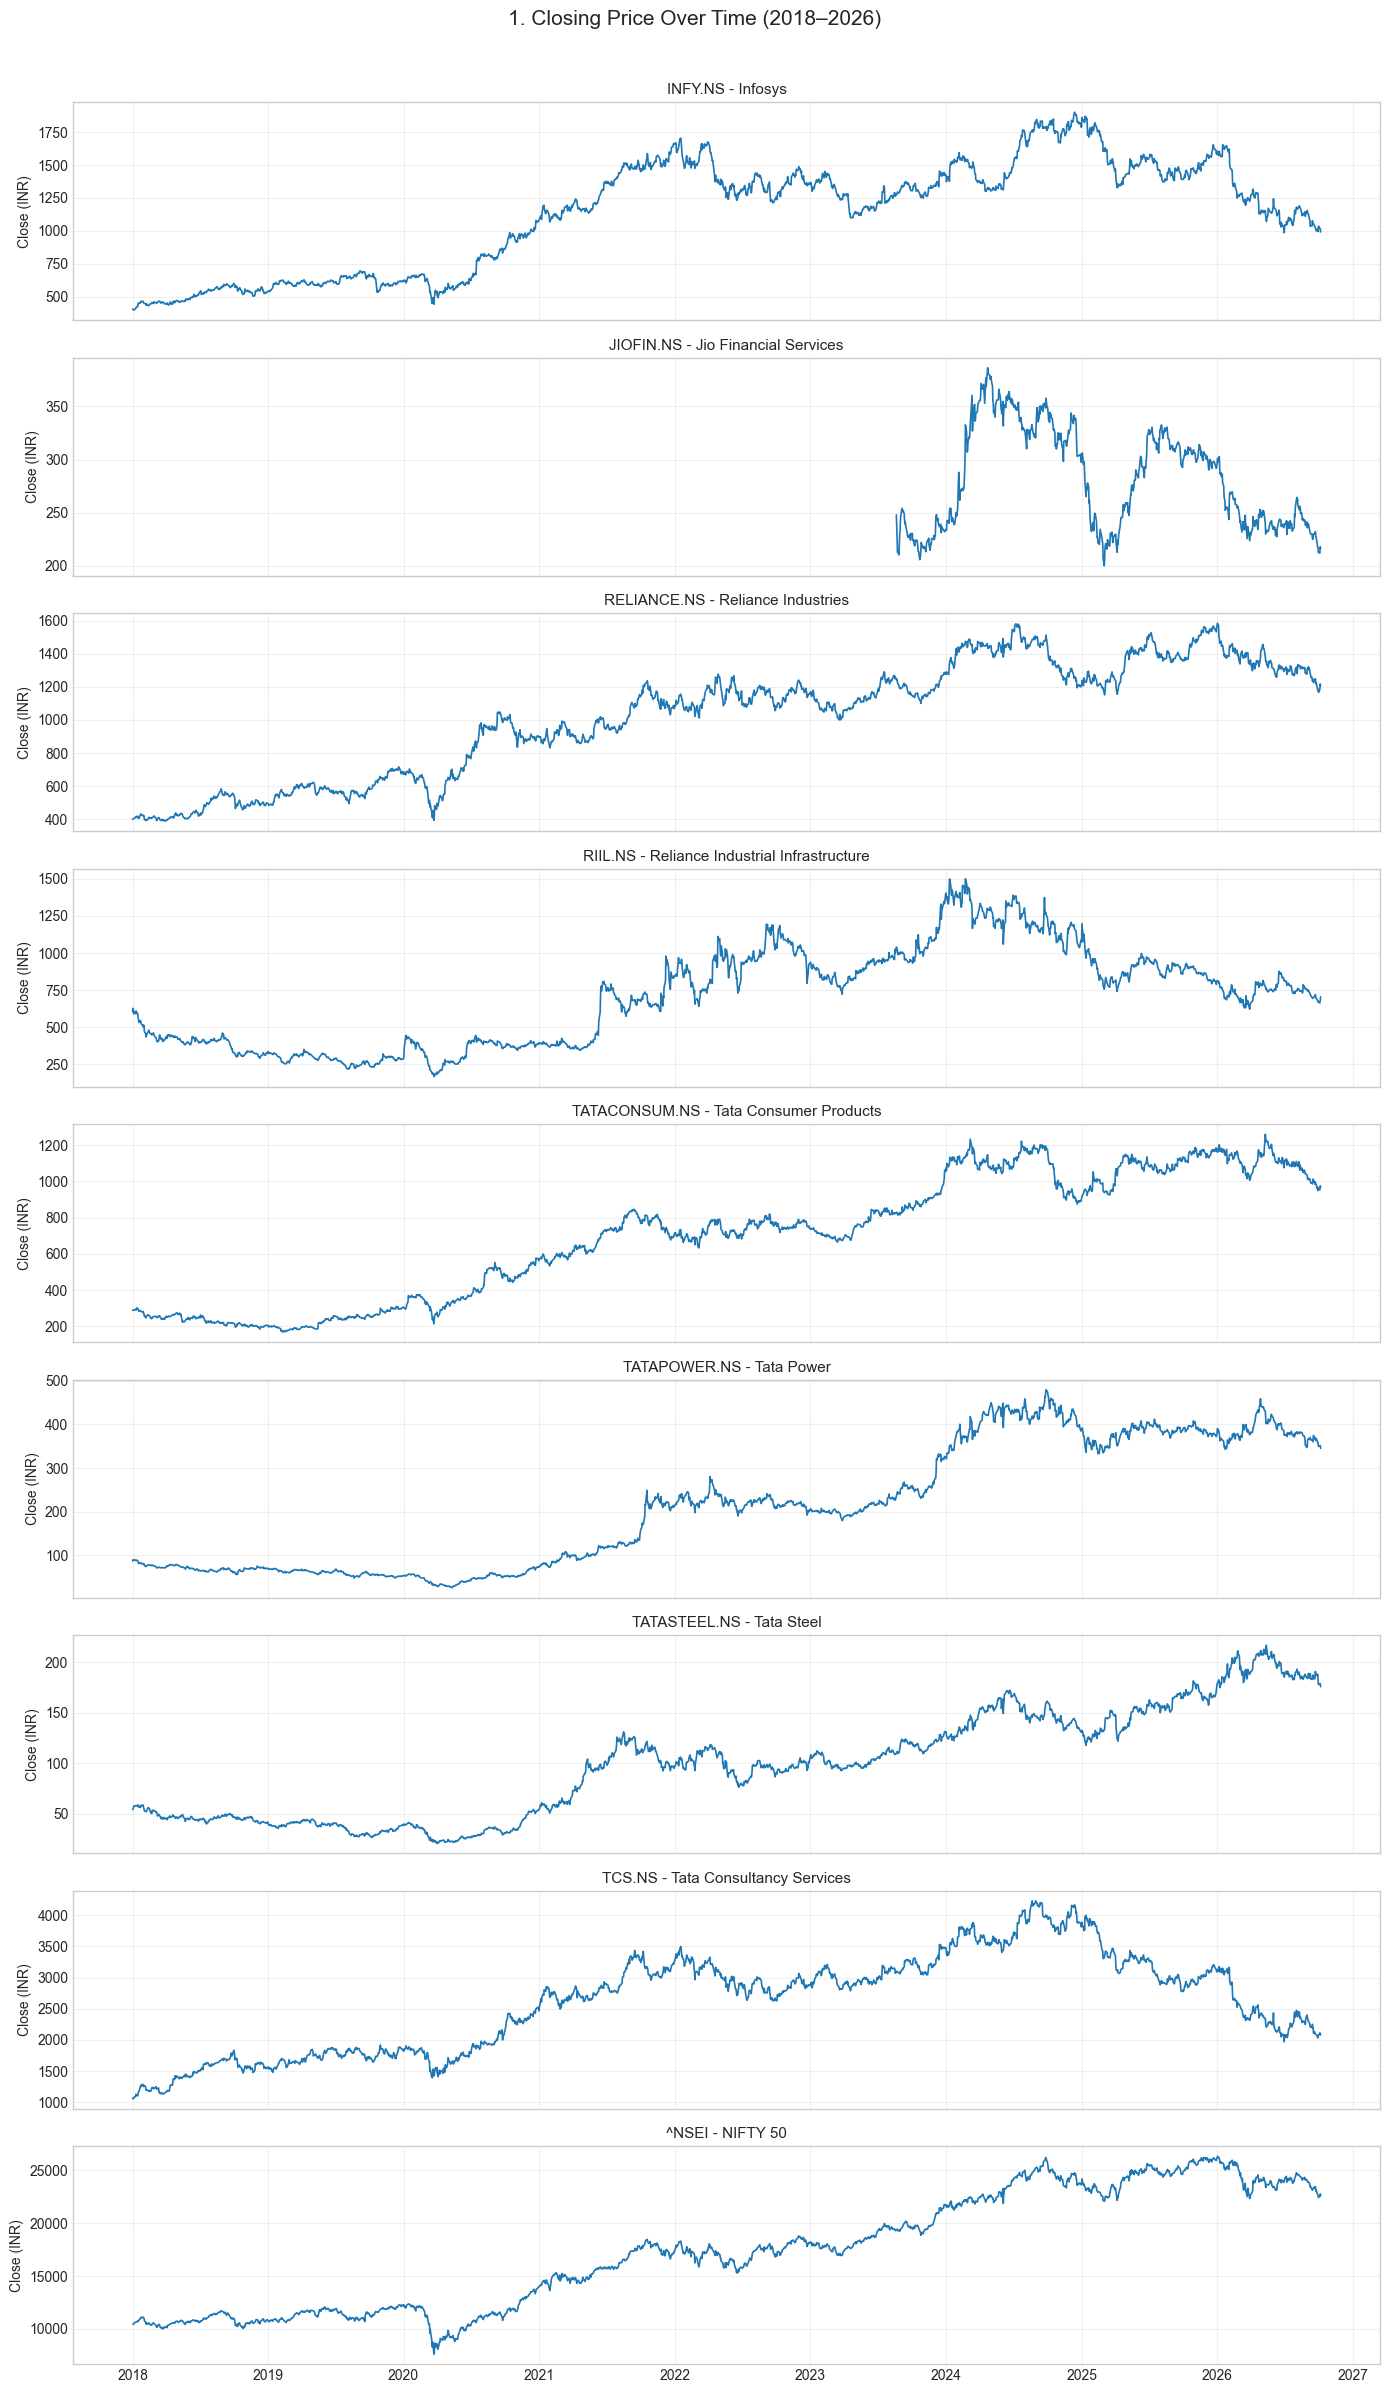

In [8]:
# 1. Closing price over time — all instruments

symbols = df["Symbol"].unique()

fig, axes = plt.subplots(
    len(symbols),
    1,
    figsize=(14, 24),
    sharex=True
)

for ax, (sym, part) in zip(axes, df.groupby("Symbol")):
    ax.plot(part["Date"], part["Close"], lw=1.2)
    ax.set_ylabel("Close (INR)")
    ax.set_title(f"{sym} - {part['Name'].iloc[0]}", fontsize=11)
    ax.grid(True, alpha=0.3)

fig.suptitle(
    "1. Closing Price Over Time (2018–2026)",
    fontsize=15,
    y=0.995
)

fig.tight_layout(rect=[0, 0, 1, 0.985])
plt.show()

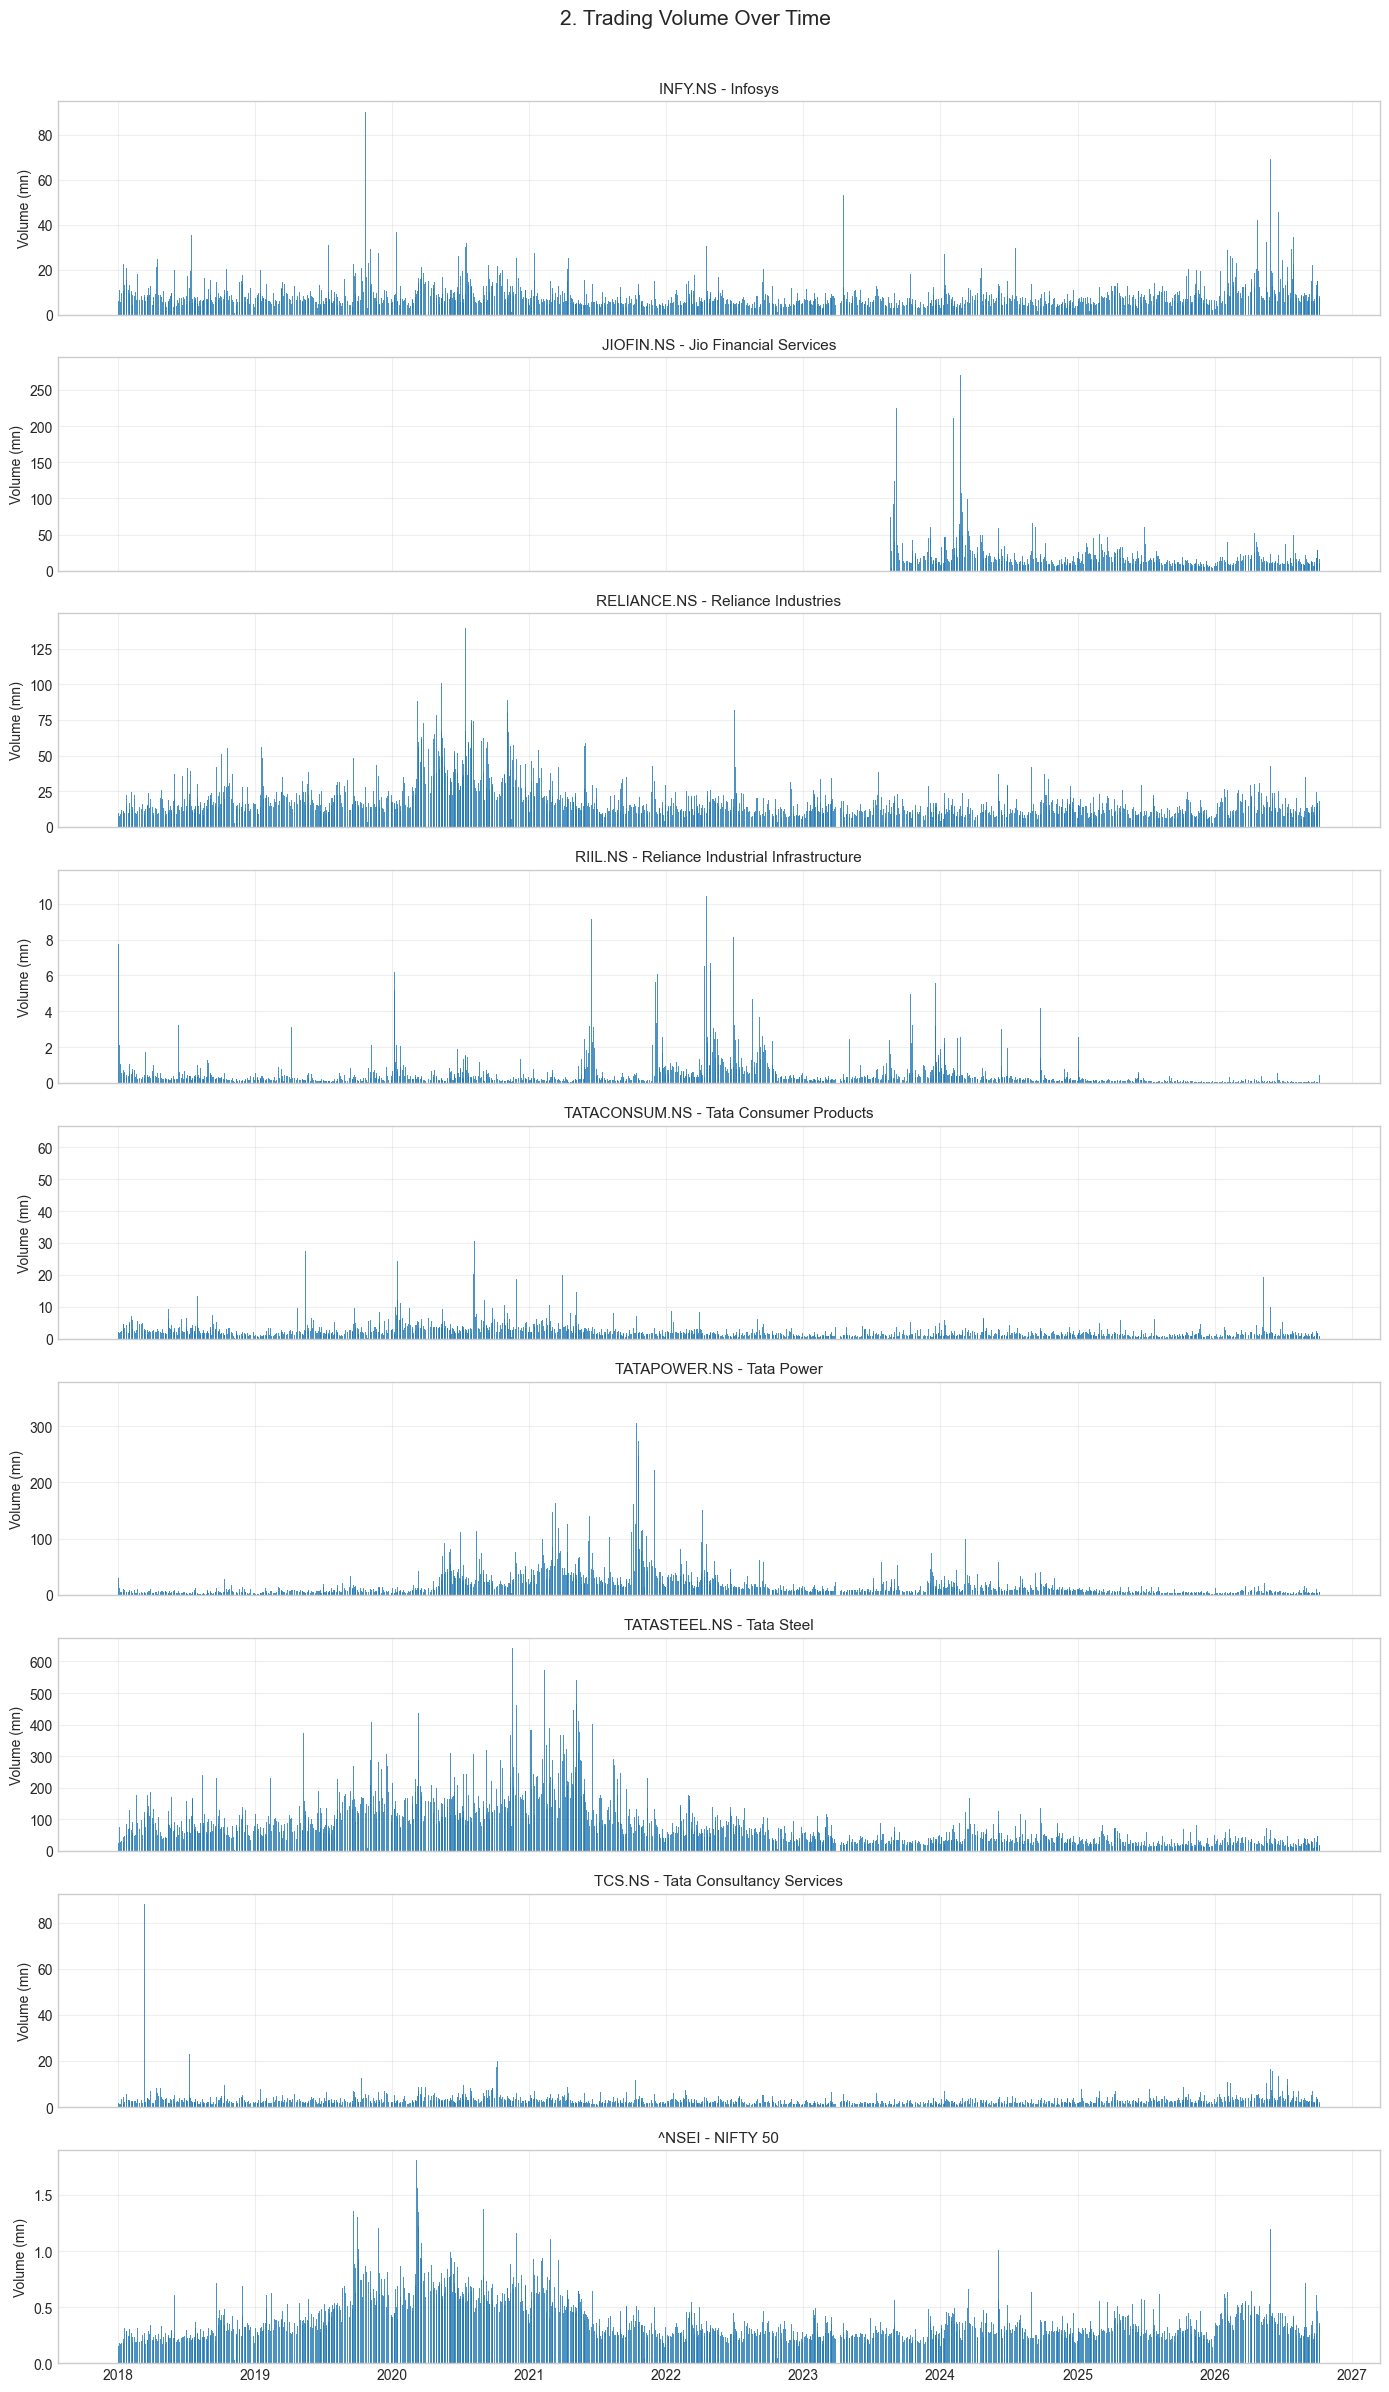

In [9]:
# 2. Trading volume over time — all instruments

symbols = df["Symbol"].unique()

fig, axes = plt.subplots(
    len(symbols),
    1,
    figsize=(14, 24),
    sharex=True
)

for ax, (sym, part) in zip(axes, df.groupby("Symbol")):
    ax.bar(
        part["Date"],
        part["Volume"] / 1e6,
        width=1.4,
        alpha=0.8
    )
    ax.set_ylabel("Volume (mn)")
    ax.set_title(f"{sym} - {part['Name'].iloc[0]}", fontsize=11)
    ax.grid(True, alpha=0.3)

fig.suptitle(
    "2. Trading Volume Over Time",
    fontsize=15,
    y=0.995
)

fig.tight_layout(rect=[0, 0, 1, 0.985])
plt.show()

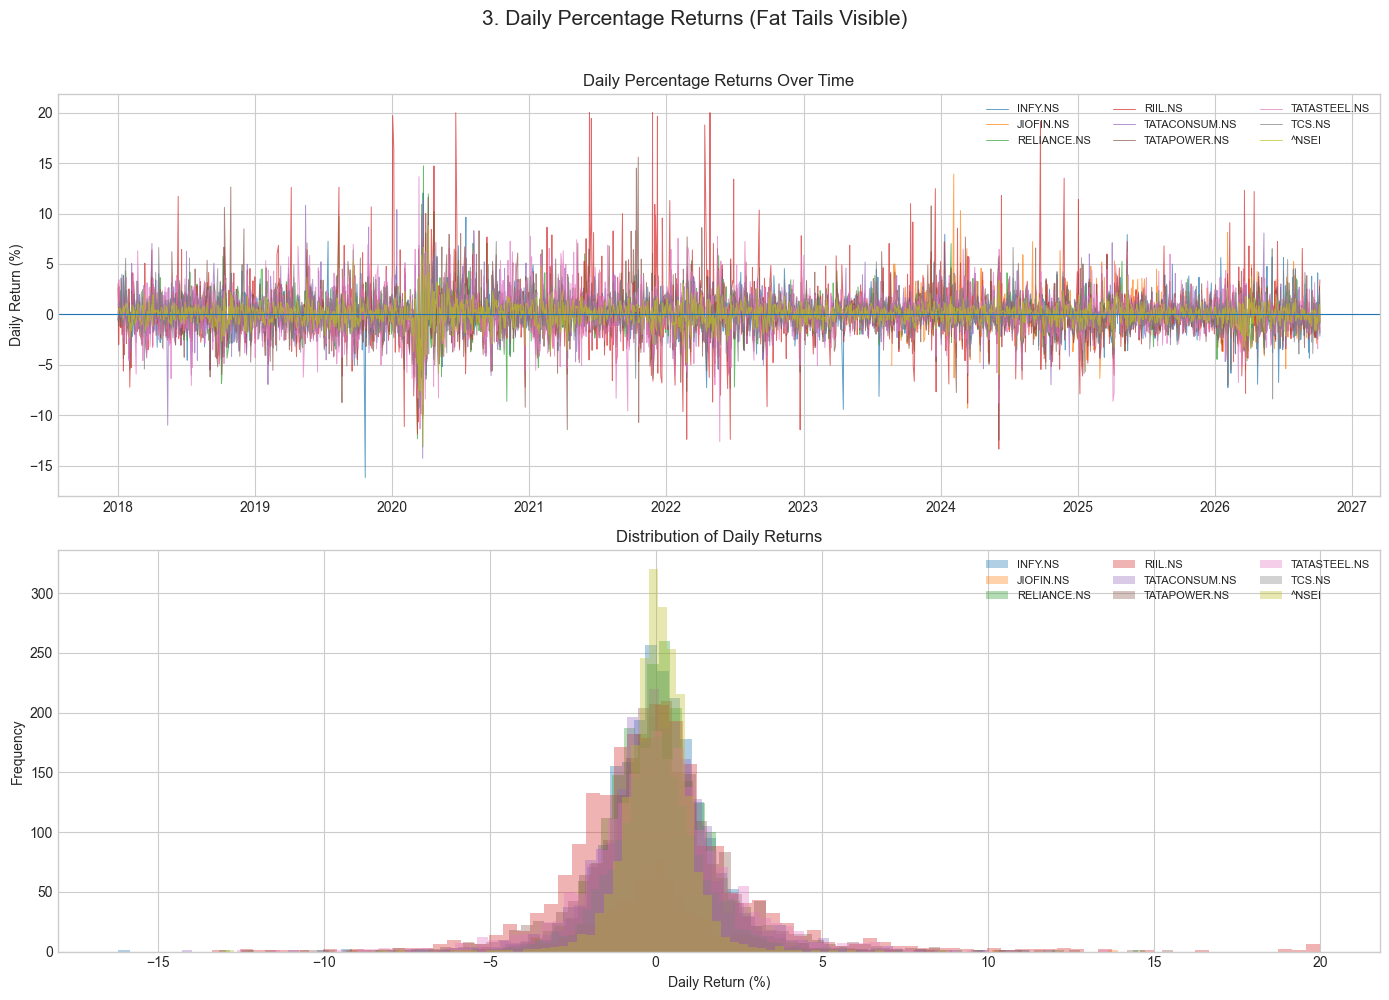

In [10]:
# 3. Daily percentage returns

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

for sym, part in df.groupby("Symbol"):
    axes[0].plot(
        part["Date"],
        part["Daily_Return"],
        lw=0.7,
        alpha=0.7,
        label=sym
    )

    axes[1].hist(
        part["Daily_Return"].dropna(),
        bins=80,
        alpha=0.35,
        label=sym
    )

axes[0].axhline(0, lw=0.8)
axes[0].set_ylabel("Daily Return (%)")
axes[0].set_title("Daily Percentage Returns Over Time")
axes[0].legend(ncol=3, fontsize=8)

axes[1].set_xlabel("Daily Return (%)")
axes[1].set_ylabel("Frequency")
axes[1].set_title("Distribution of Daily Returns")
axes[1].legend(ncol=3, fontsize=8)

fig.suptitle(
    "3. Daily Percentage Returns (Fat Tails Visible)",
    fontsize=15,
    y=0.995
)

fig.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

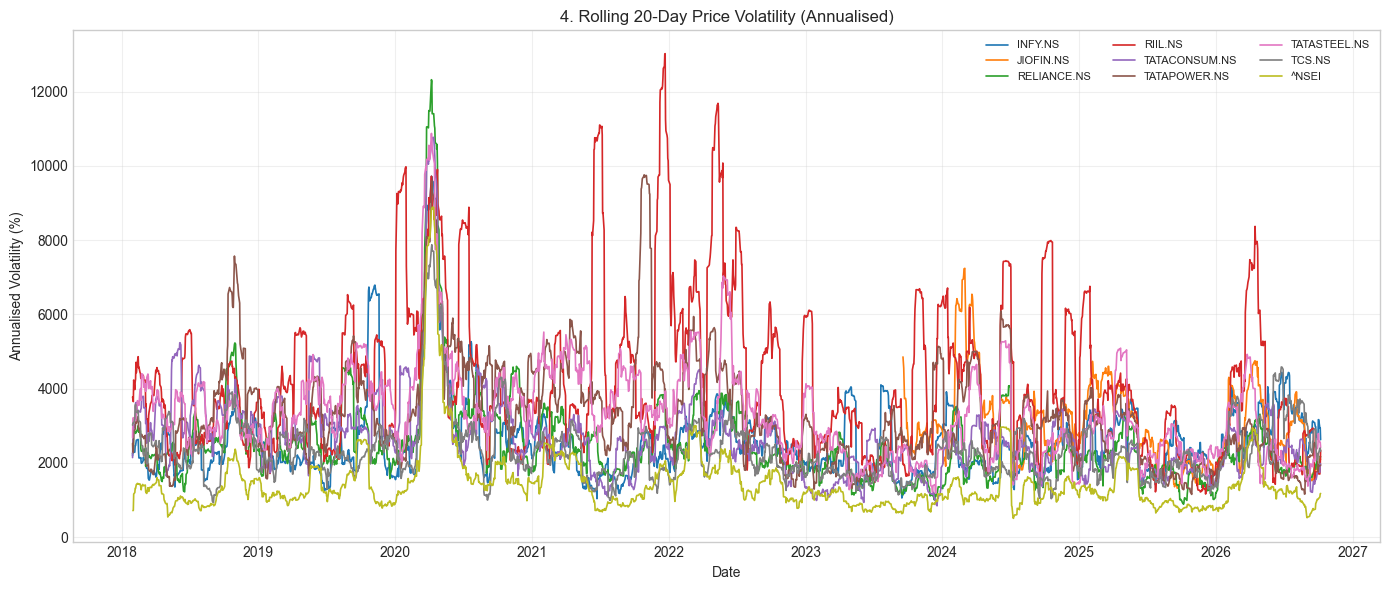

In [11]:
# 4. Price volatility — 20-day rolling standard deviation of returns, annualised

fig, ax = plt.subplots(figsize=(14, 6))

for sym, part in df.groupby("Symbol"):
    part = part.sort_values("Date")

    roll = (
        part["Daily_Return"]
        .rolling(20)
        .std()
        * np.sqrt(252)
    )

    ax.plot(
        part["Date"],
        roll * 100,
        lw=1.2,
        label=sym
    )

ax.set_ylabel("Annualised Volatility (%)")
ax.set_xlabel("Date")
ax.set_title("4. Rolling 20-Day Price Volatility (Annualised)")
ax.legend(ncol=3, fontsize=8)
ax.grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

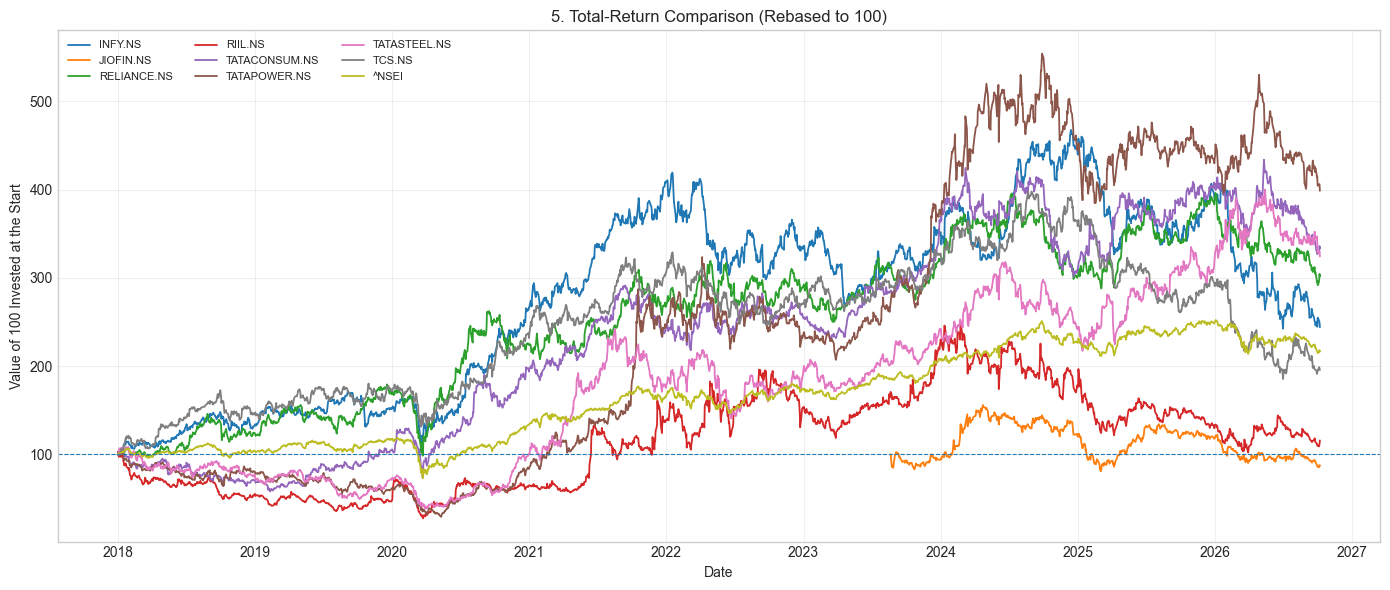

In [12]:
# 5. Comparison of all instruments, rebased to 100

fig, ax = plt.subplots(figsize=(14, 6))

for sym, part in df.groupby("Symbol"):
    part = part.sort_values("Date")

    ax.plot(
        part["Date"],
        100 * part["Close"] / part["Close"].iloc[0],
        lw=1.3,
        label=sym
    )

ax.axhline(100, lw=0.8, ls="--")

ax.set_ylabel("Value of 100 Invested at the Start")
ax.set_xlabel("Date")
ax.set_title("5. Total-Return Comparison (Rebased to 100)")
ax.legend(ncol=3, fontsize=8)
ax.grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

In [13]:
# numbers behind answers A and B
summary = pd.DataFrame({
    "ann. volatility %": df.groupby("Symbol")["Daily_Return"].std() * np.sqrt(252),
    "mean |daily return| %": df.groupby("Symbol")["Daily_Return"].apply(lambda s: s.abs().mean()),
    "worst day %": df.groupby("Symbol")["Daily_Return"].min(),
    "best day %": df.groupby("Symbol")["Daily_Return"].max(),
    "total return %": df.groupby("Symbol")["Close"].apply(
        lambda s: (s.iloc[-1] / s.iloc[0] - 1) * 100),
}).round(2)
summary.sort_values("ann. volatility %", ascending=False)

,ann. volatility %,mean |daily return| %,worst day %,best day %,total return %
Symbol,,,,,
RIIL.NS,47.27,1.91,-13.37,20.00,15.75
TATAPOWER.NS,35.55,1.54,-12.47,15.59,298.73
TATASTEEL.NS,35.29,1.59,-12.61,13.65,224.27
JIOFIN.NS,32.59,1.45,-9.30,13.91,-12.70
TATACONSUM.NS,28.79,1.27,-14.27,11.28,233.44
INFY.NS,27.60,1.21,-16.19,12.03,144.07
RELIANCE.NS,27.46,1.20,-13.15,14.72,201.91
TCS.NS,24.63,1.10,-9.41,9.85,95.62
^NSEI,16.87,0.71,-12.98,8.76,116.46


In [14]:
# volume vs price movement (answer D) and the spike calendar (answer C)
rows = []
for sym, part in df.groupby("Symbol"):
    thresh = part["Volume"].quantile(0.90)
    hi = part.loc[part["Volume"] >= thresh, "Daily_Return"].abs().median()
    lo = part.loc[part["Volume"] < thresh, "Daily_Return"].abs().median()
    rows.append({"Symbol": sym,
                 "corr(volume, |return|)": part["Volume"].corr(part["Daily_Return"].abs()),
                 "median |return| high-volume %": hi,
                 "median |return| other days %": lo,
                 "ratio": hi / lo})
vol_vs_move = pd.DataFrame(rows).set_index("Symbol").round(3)
display(vol_vs_move)

spikes = (df.sort_values(["Symbol", "Volume"], ascending=[True, False])
            .groupby("Symbol").head(5)
            .sort_values(["Symbol", "Date"])[["Symbol", "Date", "Volume", "Daily_Return"]])
display(spikes)

,"corr(volume, |return|)",median |return| high-volume %,median |return| other days %,ratio
Symbol,,,,
INFY.NS,0.54,2.38,0.83,2.88
JIOFIN.NS,0.45,2.75,0.92,2.99
RELIANCE.NS,0.52,2.08,0.83,2.49
RIIL.NS,0.53,3.50,1.17,3.01
TATACONSUM.NS,0.44,2.34,0.86,2.73
TATAPOWER.NS,0.47,2.66,0.96,2.76
TATASTEEL.NS,0.46,2.61,1.05,2.49
TCS.NS,0.42,2.03,0.72,2.81
^NSEI,0.37,0.89,0.51,1.77


Price,Symbol,Date,Volume,Daily_Return
440,INFY.NS,2019-10-22,"90,152,532.00",-16.19
441,INFY.NS,2019-10-23,"60,516,887.00",2.37
622,INFY.NS,2020-07-16,"90,432,109.00",9.63
1305,INFY.NS,2023-04-17,"53,171,705.00",-9.42
2076,INFY.NS,2026-05-29,"69,085,430.00",0.09
2174,JIOFIN.NS,2023-08-25,"281,040,185.00",0.49
2182,JIOFIN.NS,2023-09-06,"225,413,157.00",-0.86
2282,JIOFIN.NS,2024-02-05,"211,028,604.00",13.91
2296,JIOFIN.NS,2024-02-23,"270,077,122.00",10.27
2565,JIOFIN.NS,2025-03-27,"188,868,886.00",1.40


In [15]:
%pip install yfinance

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
import sys
print(sys.executable)

import yfinance
print("yfinance version:", yfinance.__version__)

c:\Users\PRERONA SINHA RAY\AppData\Local\Programs\Python\Python312\python.exe
yfinance version: 1.7.0


### Phase 2 answers

**A. Which stock shows the highest volatility?**
**Reliance Industries** — annualised volatility **27.5 %**, versus TCS **24.6 %** and the
NIFTY 50 **16.9 %**. The index is the calmest because it diversifies 50 constituents.

**B. Which stock has experienced the largest price movements?**
**Reliance**: widest single-day swing (worst day **−13.15 %**, best day **+14.72 %**),
largest average absolute daily move (**1.20 %** vs 1.10 % for TCS and 0.71 % for NIFTY)
and largest cumulative gain (**+199 %**). TCS moved the least overall (+94.7 % cumulative,
worst day −9.41 %).

**C. Are there periods where unusually high trading volume occurs?**
Yes, and the spikes cluster. All five busiest NIFTY sessions fall in **March 2020**
(COVID-19 crash: 6, 9, 13 and 18 March 2020), Reliance's peak volume days sit in
**April–September 2020** (COVID bottom plus its 2020 stake-sales programme), and TCS
clusters in **March–July 2018** and **October 2020** (results/buyback-related sessions).

**D. Is high trading volume associated with major price movements?**
**Yes.** On the busiest decile of sessions the median absolute daily move is **2.5×
(Reliance), 2.8× (TCS) and 1.8× (NIFTY)** larger than on ordinary days. Reliance's
busiest session ever (22 Apr 2020, 143 mn shares) carried a **+10.2 %** move; TCS's
busiest (13 Mar 2018) a **−5.4 %** move. That is why `Volume_Change` becomes a Phase-4
feature.

**E. Useful observations from the historical data**

* All three instruments trended up over 2018–2026 (NIFTY +118 %, Reliance +199 %,
  TCS +95 %) → the "UP" class is a slight majority, so a naive baseline is competitive.
* Volatility **clusters**: the COVID spike pushed 20-day volatility above 100 % annualised
  for Reliance, many times the calm periods → rolling volatility is a real feature and
  drives the Phase-12 risk label.
* Returns have **fat tails** (±5–14 % days in a sample whose typical day is ~1 %).
* TCS and the NIFTY behave more alike than Reliance does, so index context should help
  predict the two stocks.